In [1]:
import xarray as xr

# 修改为您自己的本地路径
file_path = r"F:\TUB\greenlandProject\ERA5LAND\ERA5pressure500&200pha.nc"

# 打开 NetCDF 文件
ds = xr.open_dataset(file_path)

# 打印基本结构信息
print("📦 数据集包含的变量:")
print(ds.data_vars)

print("\n📐 数据维度:")
print(ds.dims)

print("\n🌍 坐标范围:")
for coord in ['longitude', 'latitude', 'time']:
    if coord in ds.coords:
        print(f"{coord}: {ds[coord].values.min()} → {ds[coord].values.max()}")

# 示例：查看某个变量的结构
if 'z' in ds:
    print("\n🧭 z (位势高度) 的基本信息:")
    print(ds['z'])

# 关闭数据集
ds.close()


📦 数据集包含的变量:
Data variables:
    z        (valid_time, pressure_level, latitude, longitude) float32 ...
    u        (valid_time, pressure_level, latitude, longitude) float32 ...
    v        (valid_time, pressure_level, latitude, longitude) float32 ...
    w        (valid_time, pressure_level, latitude, longitude) float32 ...

📐 数据维度:
Frozen({'valid_time': 905, 'pressure_level': 2, 'latitude': 121, 'longitude': 261})

🌍 坐标范围:
longitude: -75.0 → -10.0
latitude: 55.0 → 85.0

🧭 z (位势高度) 的基本信息:
<xarray.DataArray 'z' (valid_time: 905, pressure_level: 2, latitude: 121,
                       longitude: 261)>
[57161610 values with dtype=float32]
Coordinates:
    number          int64 ...
  * valid_time      (valid_time) datetime64[ns] 1950-01-01 ... 2025-05-01
  * pressure_level  (pressure_level) float64 500.0 200.0
  * latitude        (latitude) float64 85.0 84.75 84.5 84.25 ... 55.5 55.25 55.0
  * longitude       (longitude) float64 -75.0 -74.75 -74.5 ... -10.25 -10.0
    expver          (v

C:\Users\11823\AppData\Local\Temp\ipykernel_16920\3820826561.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


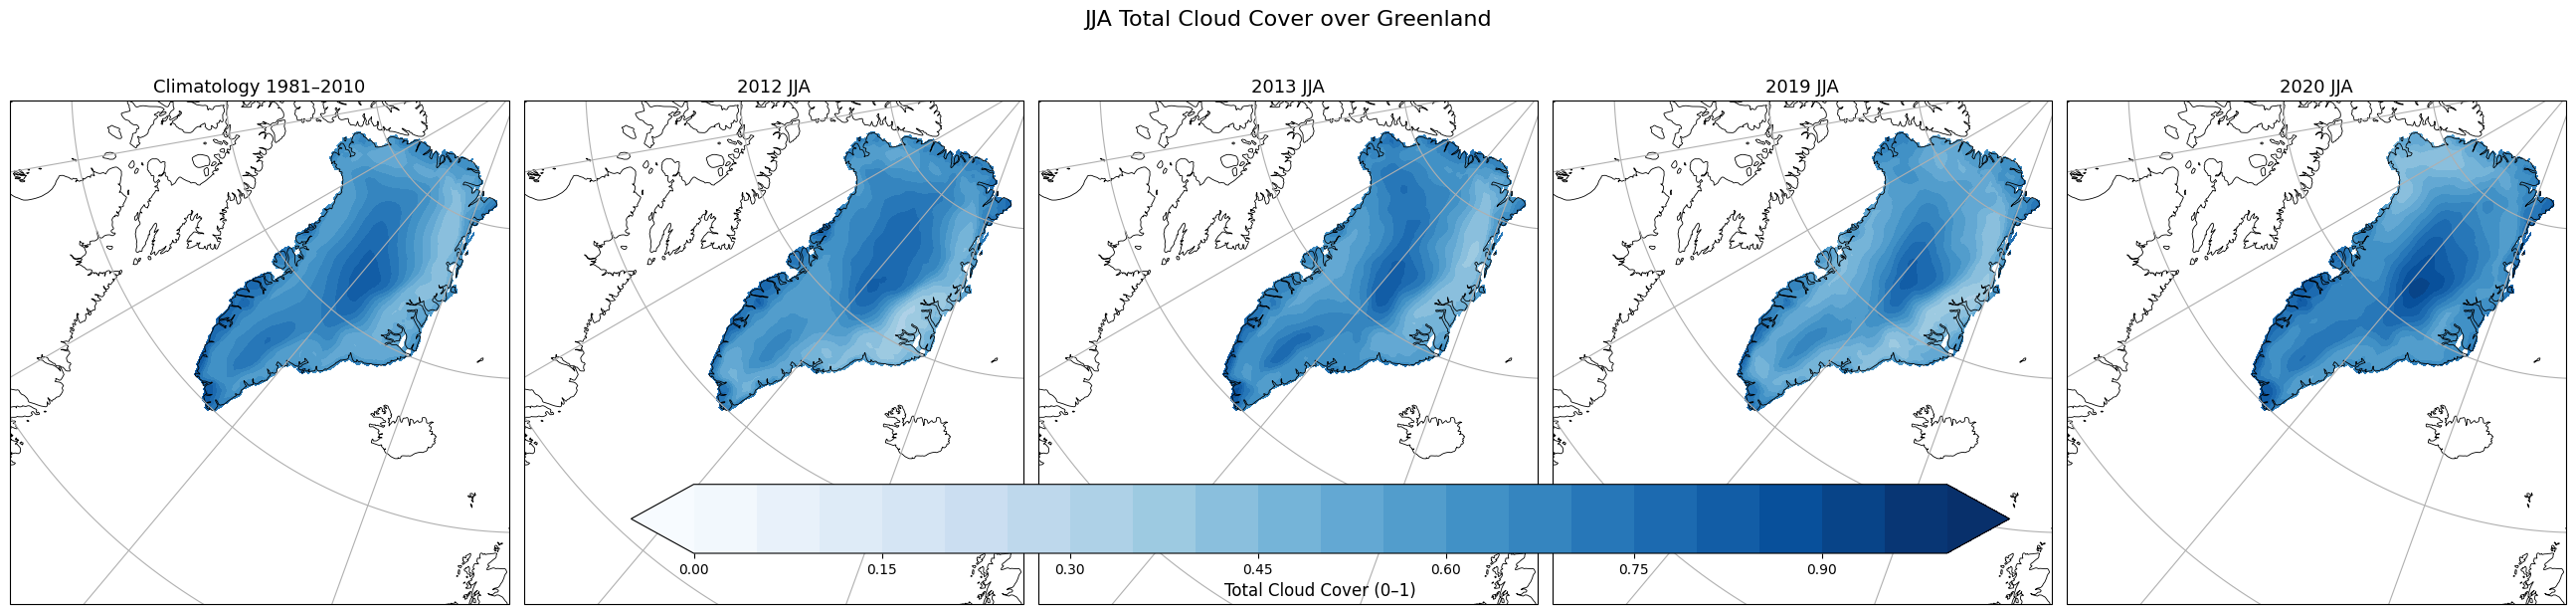

In [14]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 1️⃣ 读取文件和变量
file_path = r"F:\TUB\greenlandProject\ERA5LAND\greenland_tcc_full.nc"
ds = xr.open_dataset(file_path)

# 根据您文件结构修改这个变量名（假设是 'tcc'）
var_name = 'tcc'
tcc = ds[var_name]  # 单位应为 0–1（若为 % 则除以100）

# 如果存在 time 维度，先确认时间格式是否为 datetime64
if not np.issubdtype(tcc.time.dtype, np.datetime64):
    tcc['valid_time'] = xr.decode_cf(ds).valid_time

# 2️⃣ 设定年份
years = [2012, 2013, 2019, 2020]
summer_means = {}

for year in years:
    summer = tcc.sel(valid_valid_time=slice(f"{year}-06-01", f"{year}-08-31"))
    summer_means[year] = summer.mean(dim='valid_valid_time')

# 3️⃣ 计算 1981–2010 climatology
clim = tcc.sel(time=slice("1981-06-01", "2010-08-31"))
clim_monthly = clim.groupby('valid_time.month').mean(dim='valid_time')
clim_jja = clim_monthly.sel(month=[6, 7, 8]).mean(dim='month')
summer_means['clim'] = clim_jja

# 4️⃣ 色阶范围（总云量 0–1）
vmin, vmax = 0.0, 1.0

# 5️⃣ 绘图
proj = ccrs.NorthPolarStereo()
titles = ['Climatology 1981–2010', '2012 JJA', '2013 JJA', '2019 JJA', '2020 JJA']
keys = ['clim', 2012, 2013, 2019, 2020]

fig, axes = plt.subplots(1, 5, figsize=(26, 6), subplot_kw={'projection': proj})

for ax, key, title in zip(axes, keys, titles):
    da = summer_means[key]
    ax.set_extent([-75, -10, 55, 85], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.3)
    ax.set_title(title, fontsize=13)
    ax.gridlines(draw_labels=False)

    cf = ax.contourf(
        da.longitude,
        da.latitude,
        da,
        levels=np.linspace(vmin, vmax, 21),
        cmap='Blues',
        extend='both',
        transform=ccrs.PlateCarree()
    )

# 添加统一色条
cbar = fig.colorbar(cf, ax=axes.ravel().tolist(), orientation='horizontal', pad=0.05)
cbar.set_label("Total Cloud Cover (0–1)", fontsize=12)

plt.suptitle("JJA Total Cloud Cover over Greenland", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


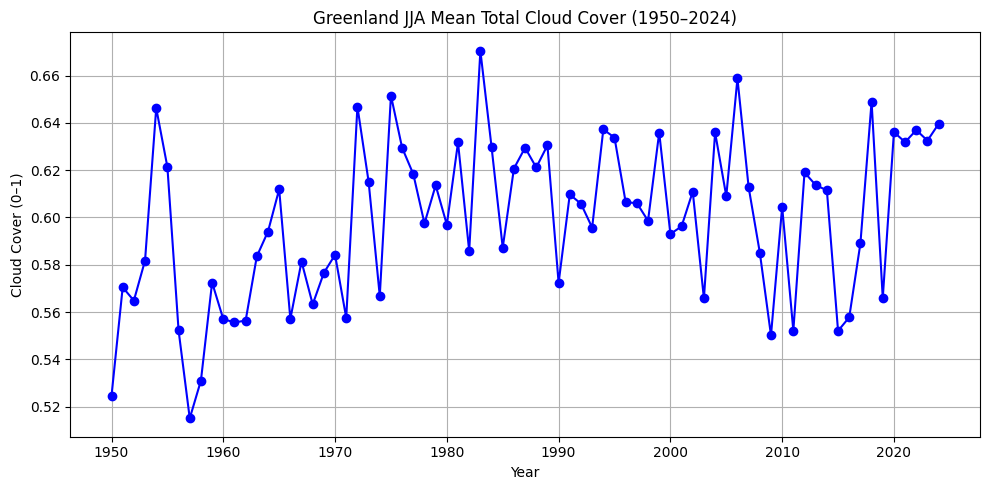

In [16]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# 1️⃣ 打开文件
file_path = r"F:\TUB\greenlandProject\ERA5LAND\greenland_tcc_full.nc"
ds = xr.open_dataset(file_path)

# 替换为你实际的变量名
tcc = ds['tcc']

# 若单位是百分比（0–100），转换为 0–1 范围
if tcc.max() > 1.1:
    tcc = tcc / 100.0

# 2️⃣ 转换为 DataFrame 风格索引（提取年份+月份）
tcc = tcc.assign_coords(year=tcc['valid_time.year'], month=tcc['valid_time.month'])

# 3️⃣ 筛选每年6–8月并按年平均
summer = tcc.where(tcc.month.isin([6, 7, 8]), drop=True)
summer_mean = summer.groupby('year').mean(dim=('valid_time', 'latitude', 'longitude'))

# 4️⃣ 提取数据用于画图
years = summer_mean['year'].values
means = summer_mean.values

# 5️⃣ 绘制折线图
plt.figure(figsize=(10, 5))
plt.plot(years, means, marker='o', linestyle='-', color='blue')
plt.title("Greenland JJA Mean Total Cloud Cover (1950–2024)")
plt.xlabel("Year")
plt.ylabel("Cloud Cover (0–1)")
plt.grid(True)
plt.tight_layout()
plt.show()


In [19]:
#-----------------------------只保留t2m这一个气象参数，然后用"E:\TUB\greenland\Greenland_shp\Gboundry.shp"裁剪它，
import xarray as xr
import geopandas as gpd
import numpy as np
from shapely.geometry import box
import rioxarray as rxr
from pathlib import Path

def crop_netcdf_by_shapefile(input_nc, shapefile_path, output_nc, variable='t2m'):
    """
    裁剪NetCDF文件，只保留指定变量并按shapefile边界裁剪
    
    Parameters:
    input_nc: str - 输入NetCDF文件路径
    shapefile_path: str - 边界shapefile路径
    output_nc: str - 输出NetCDF文件路径
    variable: str - 要保留的变量名，默认为't2m'
    """
    
    print(f"正在读取NetCDF文件: {input_nc}")
    # 读取NetCDF文件
    ds = xr.open_dataset(input_nc)
    
    print(f"原始数据集包含变量: {list(ds.data_vars.keys())}")
    print(f"原始数据集形状: {ds.dims}")
    
    # 只保留指定变量和坐标
    if variable not in ds.data_vars:
        raise ValueError(f"变量 '{variable}' 不在数据集中。可用变量: {list(ds.data_vars.keys())}")
    
    # 创建只包含目标变量的新数据集
    ds_filtered = ds[[variable]]
    print(f"已提取变量: {variable}")
    
    # 读取shapefile
    print(f"正在读取边界文件: {shapefile_path}")
    gdf = gpd.read_file(shapefile_path)
    
    # 确保shapefile是地理坐标系统
    if gdf.crs is None:
        print("警告: Shapefile没有坐标系信息，假设为WGS84")
        gdf = gdf.set_crs('EPSG:4326')
    elif not gdf.crs.is_geographic:
        print(f"将坐标系从 {gdf.crs} 转换为 WGS84")
        gdf = gdf.to_crs('EPSG:4326')
    
    # 获取边界框
    bounds = gdf.total_bounds  # [minx, miny, maxx, maxy]
    print(f"边界框: 经度 [{bounds[0]:.3f}, {bounds[2]:.3f}], 纬度 [{bounds[1]:.3f}, {bounds[3]:.3f}]")
    
    # 确定NetCDF文件中经纬度坐标的名称
    lat_names = ['latitude', 'lat', 'y']
    lon_names = ['longitude', 'lon', 'x']
    
    lat_coord = None
    lon_coord = None
    
    for name in lat_names:
        if name in ds_filtered.coords:
            lat_coord = name
            break
    
    for name in lon_names:
        if name in ds_filtered.coords:
            lon_coord = name
            break
    
    if lat_coord is None or lon_coord is None:
        raise ValueError(f"无法找到经纬度坐标。可用坐标: {list(ds_filtered.coords.keys())}")
    
    print(f"使用坐标: 纬度='{lat_coord}', 经度='{lon_coord}'")
    
    # 处理经度范围（如果需要从0-360转换为-180-180）
    lon_values = ds_filtered[lon_coord].values
    if np.max(lon_values) > 180:
        print("检测到0-360度经度，转换为-180-180度")
        # 创建新的经度值
        lon_values = np.where(lon_values > 180, lon_values - 360, lon_values)
        ds_filtered = ds_filtered.assign_coords({lon_coord: lon_values})
        # 重新排序以确保经度是递增的
        ds_filtered = ds_filtered.sortby(lon_coord)
    
    # 检查坐标的排序顺序
    lat_values = ds_filtered[lat_coord].values
    lon_values = ds_filtered[lon_coord].values
    
    print(f"纬度范围: [{lat_values.min():.3f}, {lat_values.max():.3f}]")
    print(f"经度范围: [{lon_values.min():.3f}, {lon_values.max():.3f}]")
    
    # 确定纬度是递增还是递减
    lat_ascending = lat_values[0] < lat_values[-1]
    print(f"纬度排序: {'递增' if lat_ascending else '递减'}")
    
    # 使用边界框进行初步裁剪，考虑坐标排序
    if lat_ascending:
        lat_slice = slice(bounds[1], bounds[3])  # 从小到大
    else:
        lat_slice = slice(bounds[3], bounds[1])  # 从大到小（递减排序）
    
    # 经度通常是递增的
    lon_slice = slice(bounds[0], bounds[2])
    
    print(f"裁剪范围: 纬度 {lat_slice}, 经度 {lon_slice}")
    
    # 进行裁剪
    ds_cropped = ds_filtered.sel(
        {lat_coord: lat_slice,
         lon_coord: lon_slice}
    )
    
    print(f"边界框裁剪后形状: {ds_cropped.dims}")
    
    # 检查是否裁剪成功
    if ds_cropped.dims[lat_coord] == 0 or ds_cropped.dims[lon_coord] == 0:
        print("警告: 边界框裁剪后数据为空，尝试更宽松的裁剪...")
        # 扩大边界框
        lat_buffer = 2.0  # 增加2度缓冲
        lon_buffer = 2.0
        
        expanded_bounds = [
            bounds[0] - lon_buffer,  # minx
            bounds[1] - lat_buffer,  # miny  
            bounds[2] + lon_buffer,  # maxx
            bounds[3] + lat_buffer   # maxy
        ]
        
        if lat_ascending:
            lat_slice = slice(expanded_bounds[1], expanded_bounds[3])
        else:
            lat_slice = slice(expanded_bounds[3], expanded_bounds[1])
        
        lon_slice = slice(expanded_bounds[0], expanded_bounds[2])
        
        ds_cropped = ds_filtered.sel(
            {lat_coord: lat_slice,
             lon_coord: lon_slice}
        )
        print(f"扩大边界后形状: {ds_cropped.dims}")
    
    # 如果仍然为空，使用最近邻插值方法
    if ds_cropped.dims[lat_coord] == 0 or ds_cropped.dims[lon_coord] == 0:
        print("使用最近邻方法选择数据...")
        # 找到最接近边界的坐标点
        lat_mask = (lat_values >= bounds[1] - 5) & (lat_values <= bounds[3] + 5)
        lon_mask = (lon_values >= bounds[0] - 5) & (lon_values <= bounds[2] + 5)
        
        if np.any(lat_mask) and np.any(lon_mask):
            ds_cropped = ds_filtered.isel(
                {lat_coord: lat_mask,
                 lon_coord: lon_mask}
            )
            print(f"最近邻选择后形状: {ds_cropped.dims}")
        else:
            raise ValueError("无法找到与边界重叠的数据点")
    
    # 只有在有数据的情况下才进行精确裁剪
    if ds_cropped.dims[lat_coord] > 0 and ds_cropped.dims[lon_coord] > 0:
        # 设置空间参考信息
        try:
            ds_cropped = ds_cropped.rio.write_crs("EPSG:4326")
            ds_cropped = ds_cropped.rio.set_spatial_dims(x_dim=lon_coord, y_dim=lat_coord)
            
            # 使用shapefile进行精确裁剪  
            print("正在进行精确边界裁剪...")
            ds_final = ds_cropped.rio.clip(gdf.geometry.values, gdf.crs, drop=False, invert=False)
            print("精确裁剪完成")
        except Exception as e:
            print(f"精确裁剪失败，使用边界框裁剪结果: {e}")
            ds_final = ds_cropped
    else:
        raise ValueError("裁剪后数据为空，请检查边界文件和数据覆盖范围")
    
    # 添加属性信息
    ds_final.attrs.update({
        'title': f'Cropped {variable} data for Greenland',
        'source': f'Cropped from {Path(input_nc).name}',
        'boundary': f'Clipped using {Path(shapefile_path).name}',
        'creation_date': str(pd.Timestamp.now())
    })
    
    # 保存结果前进行最终检查
    if ds_final.dims[lat_coord] == 0 or ds_final.dims[lon_coord] == 0:
        raise ValueError("最终数据集为空，无法保存")
    
    print(f"正在保存到: {output_nc}")
    
    # 确保坐标变量有正确的属性
    if lat_coord in ds_final.coords:
        ds_final[lat_coord].attrs.update({'units': 'degrees_north', 'long_name': 'latitude'})
    if lon_coord in ds_final.coords:  
        ds_final[lon_coord].attrs.update({'units': 'degrees_east', 'long_name': 'longitude'})
    
    # 保存文件
    encoding = {var: {'zlib': True, 'complevel': 4} for var in ds_final.data_vars}
    ds_final.to_netcdf(output_nc, encoding=encoding)
    
    print("处理完成!")
    print(f"最终数据集形状: {ds_final.dims}")
    print(f"最终数据集变量: {list(ds_final.data_vars.keys())}")
    
    # 显示一些统计信息
    if variable in ds_final.data_vars:
        var_data = ds_final[variable]
        valid_data = var_data.where(~np.isnan(var_data))
        print(f"{variable} 统计信息:")
        print(f"  最小值: {float(valid_data.min()):.3f}")
        print(f"  最大值: {float(valid_data.max()):.3f}")
        print(f"  平均值: {float(valid_data.mean()):.3f}")
        print(f"  有效数据点: {int(valid_data.count())}")
    
    # 关闭数据集
    ds.close()
    ds_filtered.close()
    if 'ds_cropped' in locals():
        ds_cropped.close()
    
    return ds_final

# 主函数
if __name__ == "__main__":
    import pandas as pd
    
    # 文件路径
    input_file = r"F:\TUB\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature.nc"
    shapefile = r"E:\TUB\greenland\Greenland_shp\Gboundry.shp"
    output_file = "greenlandT2M.nc"
    
    try:
        # 执行裁剪
        result = crop_netcdf_by_shapefile(
            input_nc=input_file,
            shapefile_path=shapefile,
            output_nc=output_file,
            variable='t2m'
        )
        
        print(f"\n成功生成裁剪后的文件: {output_file}")
        
        # 显示一些基本信息
        # 确定时间坐标名称
        time_coord = None
        time_names = ['valid_time', 'time', 't']
        for name in time_names:
            if name in result.coords:
                time_coord = name
                break
        
        if time_coord:
            print(f"时间范围: {result[time_coord].min().values} 到 {result[time_coord].max().values}")
        
        # 确定经纬度坐标名称（使用之前找到的）
        lat_names = ['latitude', 'lat', 'y']
        lon_names = ['longitude', 'lon', 'x']
        
        lat_coord_final = None
        lon_coord_final = None
        
        for name in lat_names:
            if name in result.coords:
                lat_coord_final = name
                break
        
        for name in lon_names:
            if name in result.coords:
                lon_coord_final = name
                break
        
        if lat_coord_final and lon_coord_final:
            print(f"空间范围: 经度 [{result[lon_coord_final].min().values:.3f}, {result[lon_coord_final].max().values:.3f}]")
            print(f"         纬度 [{result[lat_coord_final].min().values:.3f}, {result[lat_coord_final].max().values:.3f}]")
        
    except Exception as e:
        print(f"处理过程中出现错误: {e}")
        import traceback
        traceback.print_exc()

正在读取NetCDF文件: F:\TUB\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature.nc
原始数据集包含变量: ['t2m', 'asn', 'fal', 'slhf', 'str', 'ssrd', 'strd', 'u10', 'v10', 'sp']
原始数据集形状: Frozen({'valid_time': 902, 'latitude': 351, 'longitude': 751})
已提取变量: t2m
正在读取边界文件: E:\TUB\greenland\Greenland_shp\Gboundry.shp
边界框: 经度 [-73.054, -11.483], 纬度 [59.790, 83.651]
使用坐标: 纬度='latitude', 经度='longitude'
纬度范围: [55.000, 90.000]
经度范围: [-80.000, -5.000]
纬度排序: 递减
裁剪范围: 纬度 slice(83.65143167654469, 59.790275573730526, None), 经度 slice(-73.0536041259765, -11.483067700466904, None)
边界框裁剪后形状: Frozen({'valid_time': 902, 'latitude': 239, 'longitude': 616})
正在进行精确边界裁剪...
精确裁剪完成
正在保存到: greenlandT2M.nc
处理完成!
最终数据集形状: Frozen({'valid_time': 902, 'latitude': 239, 'longitude': 616})
最终数据集变量: ['t2m']
t2m 统计信息:
  最小值: 225.521
  最大值: 288.015
  平均值: 252.977
  有效数据点: 59370542

成功生成裁剪后的文件: greenlandT2M.nc
时间范围: 1950-01-01T00:00:00.000000000 到 2025-02-01T00:00:00.000000000
空间范围: 经度 [-73.000, -11.500]
         纬度 [59.800, 83.600]


C:\Users\11823\AppData\Local\Temp\ipykernel_16920\257600123.py:67: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


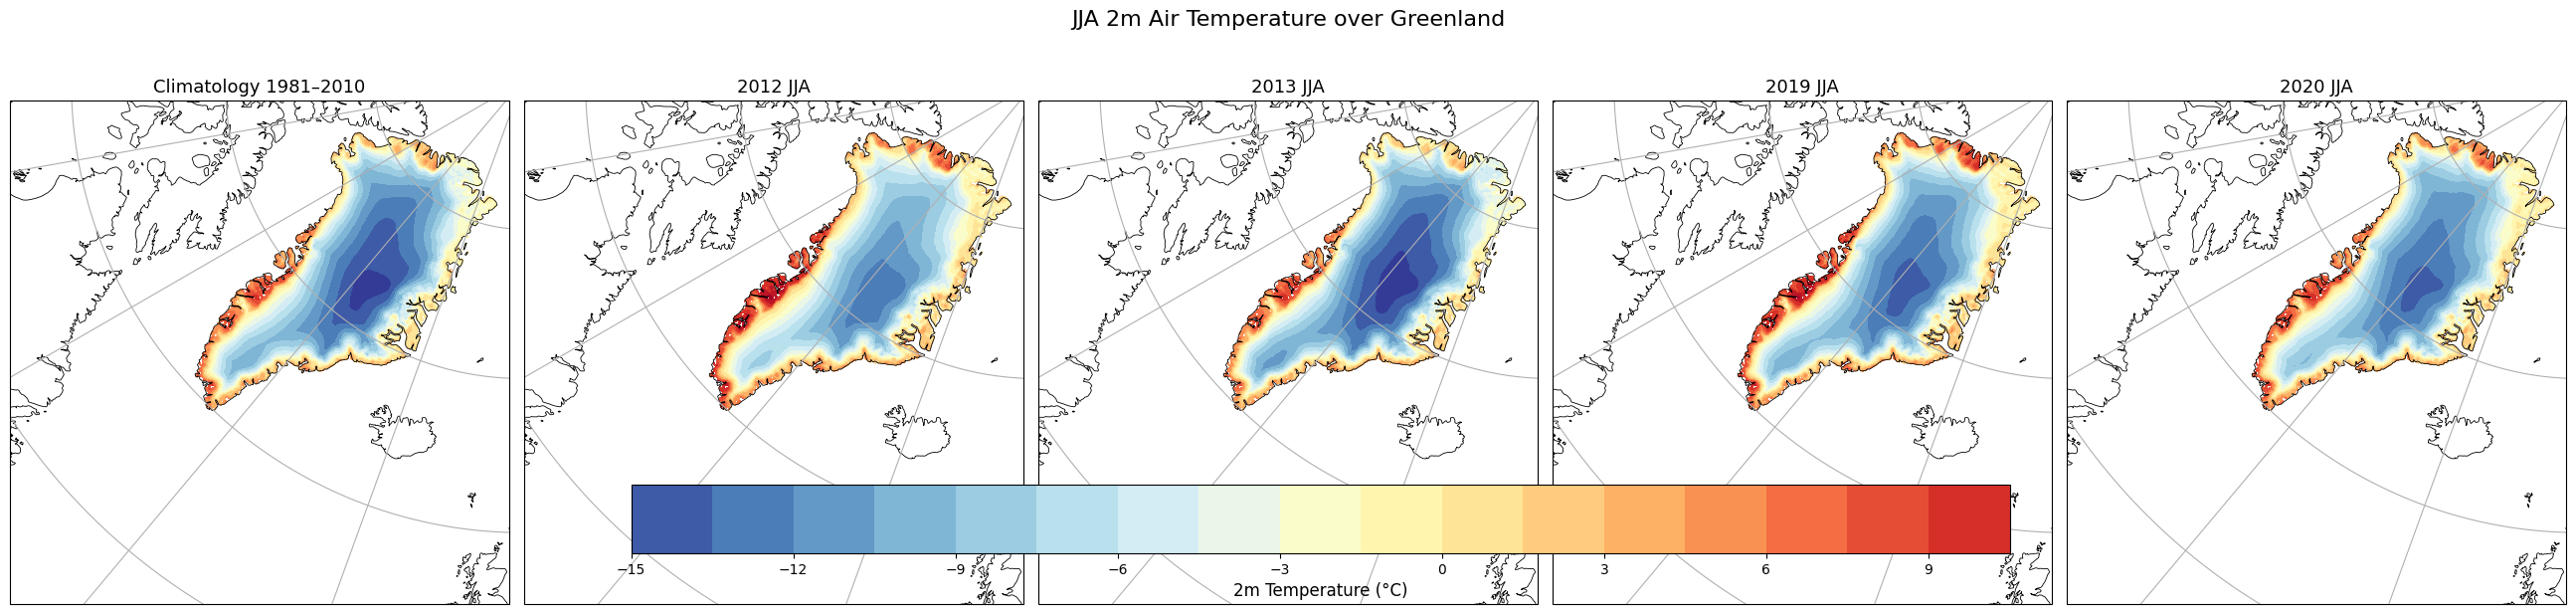

In [21]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 1️⃣ 读取 T2M 文件
file_path = r"F:\TUB\greenlandProject\ERA5LAND\ProcessFile\greenlandT2M.nc"
ds = xr.open_dataset(file_path)

# 修改为你实际的变量名，假设是 't2m'
t2m = ds['t2m']

# 单位转换（K → °C）
if t2m.max() > 100:
    t2m = t2m - 273.15

# 2️⃣ 构造目标年份与 climatology
years = [2012, 2013, 2019, 2020]
summer_means = {}

for year in years:
    summer = t2m.sel(valid_time=slice(f"{year}-06-01", f"{year}-08-31"))
    summer_means[year] = summer.mean(dim='valid_time')

# 3️⃣ 1981–2010 climatology
clim = t2m.sel(valid_time=slice("1981-06-01", "2010-08-31"))
clim_monthly = clim.groupby('valid_time.month').mean(dim='valid_time')
clim_jja = clim_monthly.sel(month=[6, 7, 8]).mean(dim='month')
summer_means['clim'] = clim_jja

# 4️⃣ 色阶范围（气温）
vmin = min(float(z.min().values) for z in summer_means.values())
vmax = max(float(z.max().values) for z in summer_means.values())

# 5️⃣ 绘图
proj = ccrs.NorthPolarStereo()
titles = ['Climatology 1981–2010', '2012 JJA', '2013 JJA', '2019 JJA', '2020 JJA']
keys = ['clim', 2012, 2013, 2019, 2020]

fig, axes = plt.subplots(1, 5, figsize=(26, 6), subplot_kw={'projection': proj})

for ax, key, title in zip(axes, keys, titles):
    da = summer_means[key]
    ax.set_extent([-75, -10, 55, 85], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.3)
    ax.set_title(title, fontsize=13)
    ax.gridlines(draw_labels=False)

    cf = ax.contourf(
        da.longitude,
        da.latitude,
        da,
        levels=20,
        cmap='RdYlBu_r',
        vmin=vmin,
        vmax=vmax,
        transform=ccrs.PlateCarree()
    )

# 6️⃣ 添加色条
cbar = fig.colorbar(cf, ax=axes.ravel().tolist(), orientation='horizontal', pad=0.05)
cbar.set_label("2m Temperature (°C)", fontsize=12)

plt.suptitle("JJA 2m Air Temperature over Greenland", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


C:\Users\11823\AppData\Local\Temp\ipykernel_16920\660948252.py:67: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


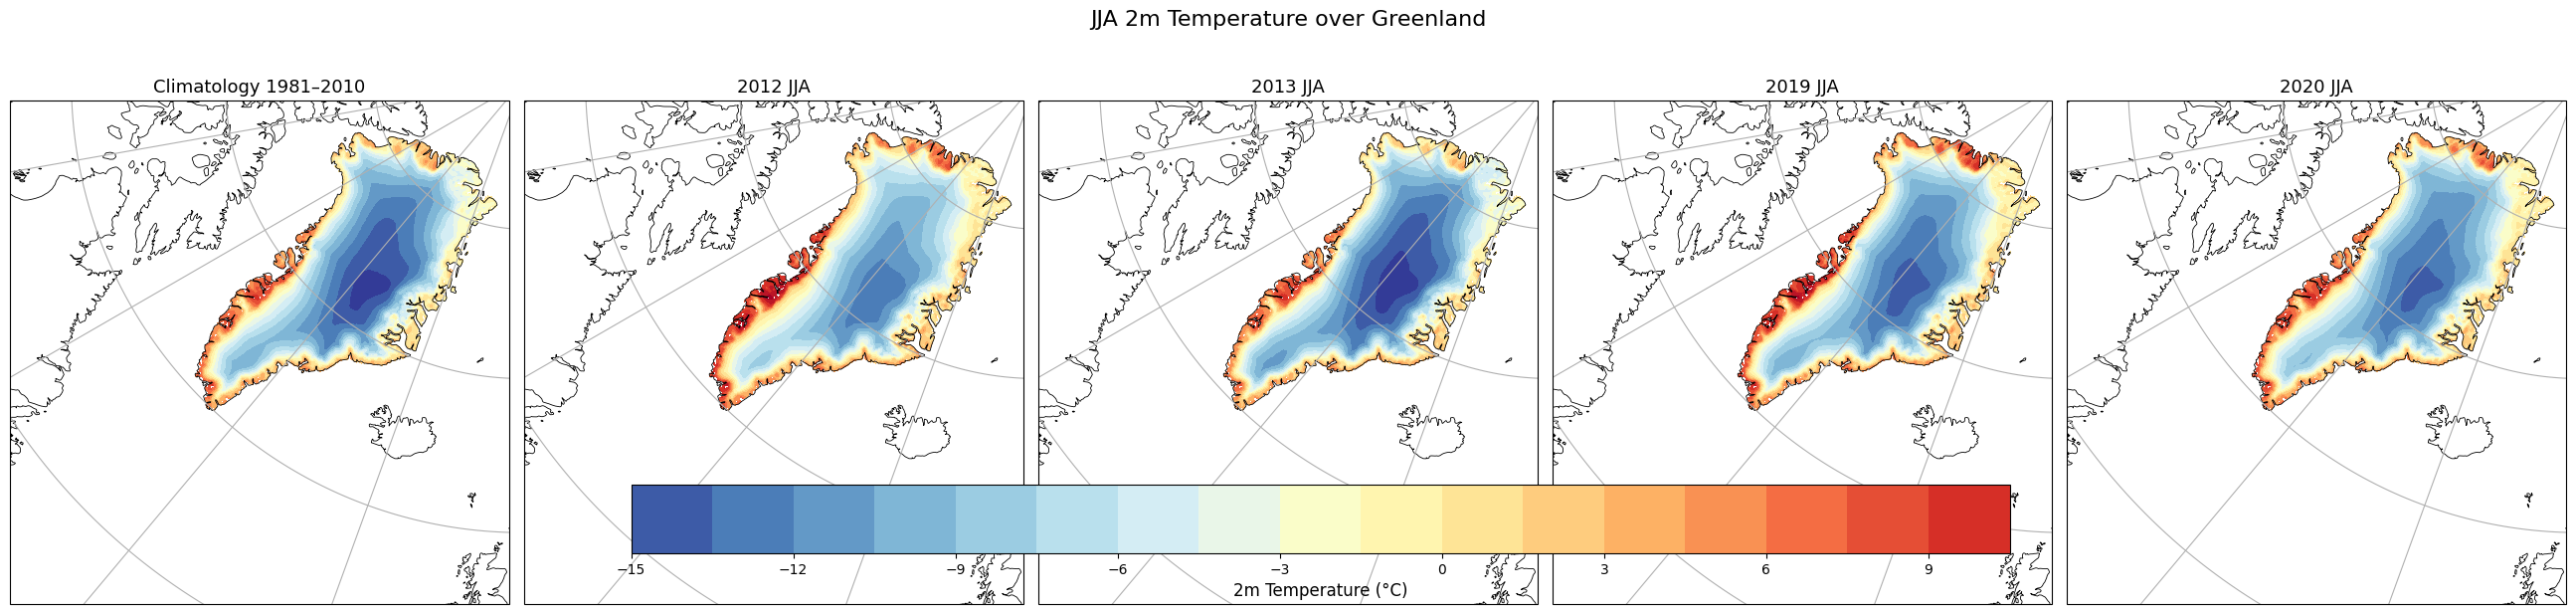

In [22]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 1️⃣ 读取数据
file_path = r"F:\TUB\greenlandProject\ERA5LAND\ProcessFile\greenlandT2M.nc"
ds = xr.open_dataset(file_path)
t2m = ds['t2m']

# 时间维是 valid_time
t2m = t2m.assign_coords(year=t2m['valid_time.year'], month=t2m['valid_time.month'])

# 单位判断：K 转为 °C
if t2m.max() > 100:
    t2m = t2m - 273.15

# 2️⃣ 每年 6–8 月平均
years = [2012, 2013, 2019, 2020]
summer_means = {}

for year in years:
    jja = t2m.where((t2m.year == year) & t2m.month.isin([6, 7, 8]), drop=True)
    summer_means[year] = jja.mean(dim='valid_time')

# 3️⃣ Climatology：1981–2010 JJA
clim = t2m.where((t2m.year >= 1981) & (t2m.year <= 2010) & t2m.month.isin([6, 7, 8]), drop=True)
clim_mean = clim.groupby('month').mean(dim='valid_time').sel(month=[6, 7, 8]).mean(dim='month')
summer_means['clim'] = clim_mean

# 4️⃣ 统一色阶
vmin = min(float(z.min()) for z in summer_means.values())
vmax = max(float(z.max()) for z in summer_means.values())

# 5️⃣ 绘图
proj = ccrs.NorthPolarStereo()
titles = ['Climatology 1981–2010', '2012 JJA', '2013 JJA', '2019 JJA', '2020 JJA']
keys = ['clim', 2012, 2013, 2019, 2020]

fig, axes = plt.subplots(1, 5, figsize=(26, 6), subplot_kw={'projection': proj})

for ax, key, title in zip(axes, keys, titles):
    da = summer_means[key]
    ax.set_extent([-75, -10, 55, 85], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.3)
    ax.set_title(title, fontsize=13)
    ax.gridlines(draw_labels=False)

    cf = ax.contourf(
        da.longitude,
        da.latitude,
        da,
        levels=20,
        cmap='RdYlBu_r',
        vmin=vmin,
        vmax=vmax,
        transform=ccrs.PlateCarree()
    )

# 色条
cbar = fig.colorbar(cf, ax=axes.ravel().tolist(), orientation='horizontal', pad=0.05)
cbar.set_label("2m Temperature (°C)", fontsize=12)

plt.suptitle("JJA 2m Temperature over Greenland", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()


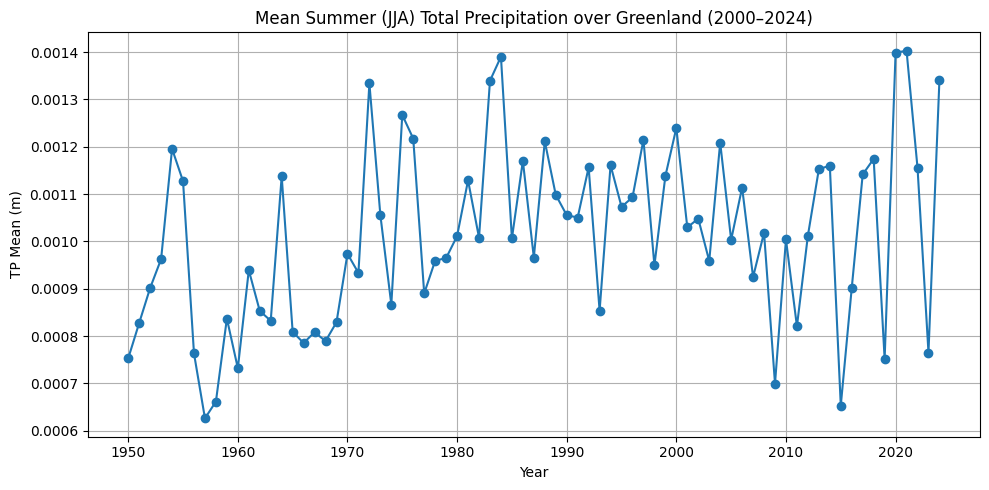

In [32]:
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 📂 文件路径
file_path = r"F:\TUB\greenlandProject\ERA5LAND\ProcessFile\Greenland_precipitation.nc"

# 1️⃣ 打开 NetCDF 文件
ds = xr.open_dataset(file_path)

# 2️⃣ 提取变量
tp = ds['tp']  # total precipitation
time = ds['valid_time']

# 3️⃣ 转换为 DataFrame（计算区域均值）
tp_mean = tp.mean(dim=['latitude', 'longitude'])  # 空间均值
df = tp_mean.to_dataframe().reset_index()

# 4️⃣ 时间转换并筛选年份
df['year'] = df['valid_time'].dt.year
df['month'] = df['valid_time'].dt.month

# 5️⃣ 筛选 2000–2024 年的 6–8 月
df_season = df[(df['year'] >= 1950) & (df['year'] <= 2024) & (df['month'].isin([6, 7, 8]))]

# 6️⃣ 按年分组，计算夏季（6–8月）平均降水
summer_tp = df_season.groupby('year')['tp'].mean()

# 7️⃣ 绘图
plt.figure(figsize=(10, 5))
plt.plot(summer_tp.index, summer_tp.values, marker='o', linestyle='-')
plt.title("Mean Summer (JJA) Total Precipitation over Greenland (2000–2024)")
plt.xlabel("Year")
plt.ylabel("TP Mean (m)")
plt.grid(True)
plt.tight_layout()
plt.show()


C:\Users\11823\AppData\Local\Temp\ipykernel_16920\3943031624.py:62: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


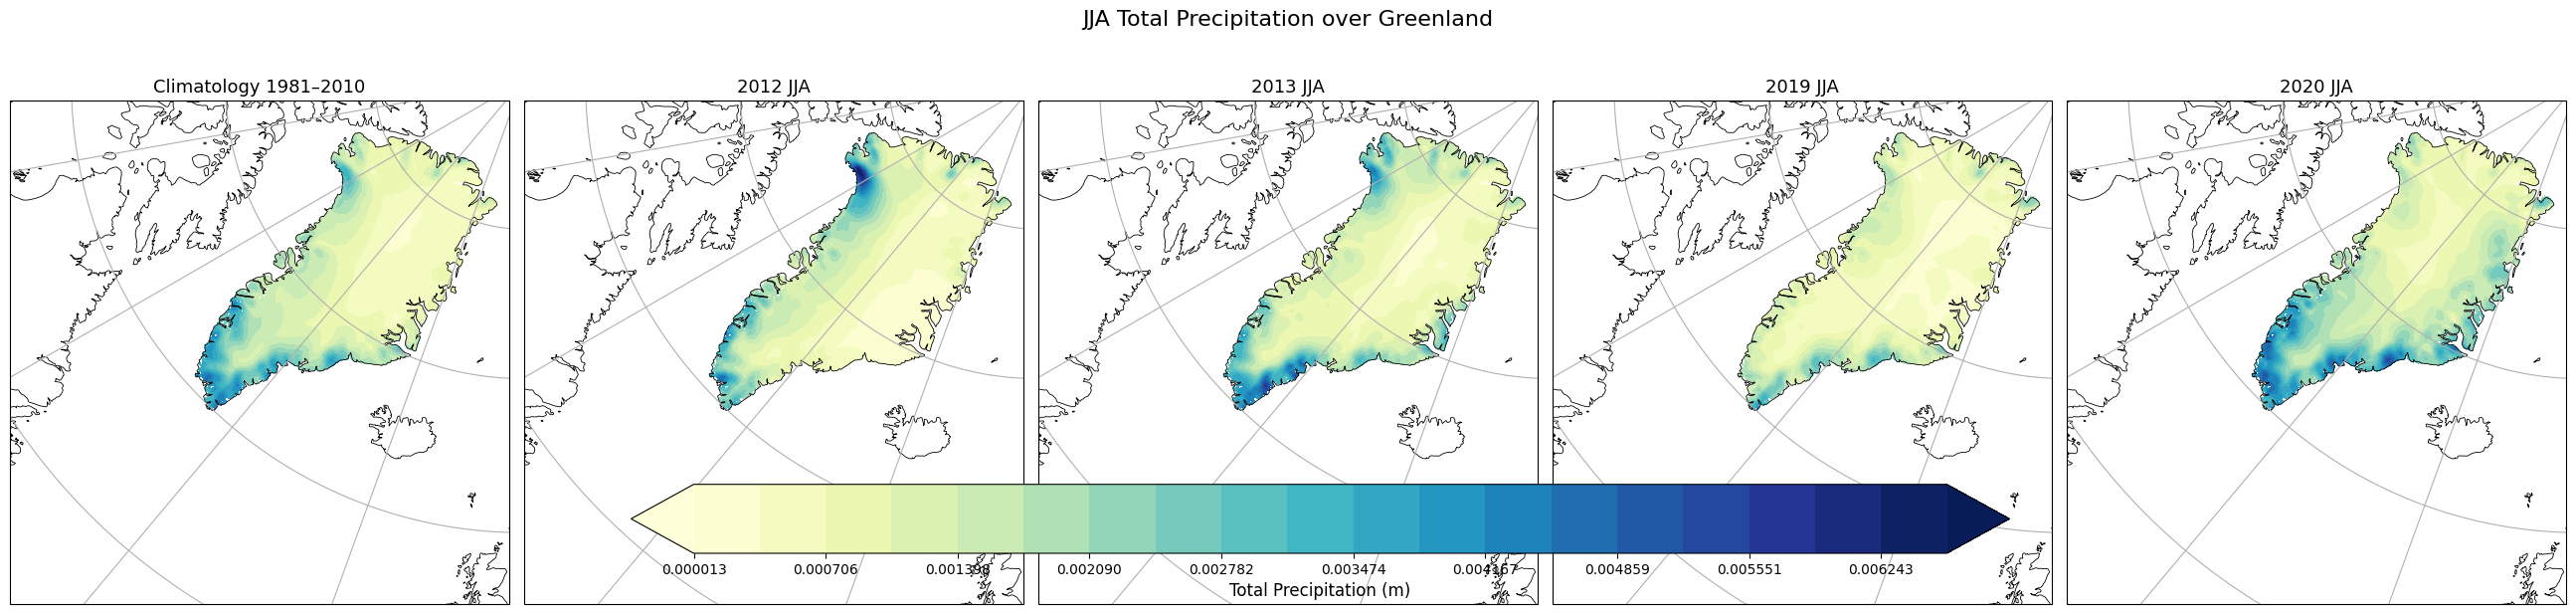

In [31]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# 1️⃣ 读取数据
file_path = r"F:\TUB\greenlandProject\ERA5LAND\ProcessFile\Greenland_precipitation.nc"
ds = xr.open_dataset(file_path)
tp = ds['tp']  # 降水变量（通常单位为 m）

# 2️⃣ 转换坐标为年+月
tp = tp.assign_coords(year=tp['valid_time.year'], month=tp['valid_time.month'])

# 3️⃣ 筛选夏季6–8月 & 年份
years = [2012, 2013, 2019, 2020]
summer_means = {}

for year in years:
    jja = tp.where((tp.year == year) & tp.month.isin([6, 7, 8]), drop=True)
    summer_means[year] = jja.mean(dim='valid_time')

# 4️⃣ Climatology: 1981–2010年JJA
clim = tp.where((tp.year >= 1981) & (tp.year <= 2010) & tp.month.isin([6, 7, 8]), drop=True)
clim_mean = clim.groupby('month').mean(dim='valid_time').sel(month=[6, 7, 8]).mean(dim='month')
summer_means['clim'] = clim_mean

# 5️⃣ 色阶范围（单位 m）
vmin = min(float(da.min()) for da in summer_means.values())
vmax = max(float(da.max()) for da in summer_means.values())

# 6️⃣ 绘图
proj = ccrs.NorthPolarStereo()
titles = ['Climatology 1981–2010', '2012 JJA', '2013 JJA', '2019 JJA', '2020 JJA']
keys = ['clim', 2012, 2013, 2019, 2020]

fig, axes = plt.subplots(1, 5, figsize=(26, 6), subplot_kw={'projection': proj})

for ax, key, title in zip(axes, keys, titles):
    da = summer_means[key]
    ax.set_extent([-75, -10, 55, 85], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.3)
    ax.set_title(title, fontsize=13)
    ax.gridlines(draw_labels=False)

    cf = ax.contourf(
        da.longitude,
        da.latitude,
        da,
        levels=np.linspace(vmin, vmax, 20),
        cmap='YlGnBu',
        extend='both',
        transform=ccrs.PlateCarree()
    )

# 7️⃣ 色条
cbar = fig.colorbar(cf, ax=axes.ravel().tolist(), orientation='horizontal', pad=0.05)
cbar.set_label("Total Precipitation (m)", fontsize=12)

plt.suptitle("JJA Total Precipitation over Greenland", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()
